# Проект по машинному обучению:
**Авторы:**  
Ерофеев Илья  
ИД24-1  

**Предметная область:** финансы / банковское кредитование  

### Идея проекта
Цель проекта — построить и исследовать модель машинного обучения, которая по финансовым и демографическим характеристикам заявителя предсказывает, будет ли ему одобрен банковский кредит.

### Практическая значимость
Такая модель может использоваться для:
- автоматизации первичной оценки кредитоспособности клиентов;
- снижения числа дефолтных кредитов и финансовых потерь банка;
- ускорения процесса принятия решений по кредитным заявкам;
- персонализации кредитных предложений для разных категорий клиентов.

## 1. Постановка задачи:

### Бизнес-задача
Банку необходимо эффективно оценивать кредитоспособность заявителей, чтобы минимизировать риски невозврата кредита и при этом не отказывать платёжеспособным клиентам. Ручная проверка каждой заявки трудоёмка и подвержена субъективности.

### ML-задача
Необходимо по признакам заявки предсказать целевую переменную **loan_status**:  
1 — кредит одобрен;  
0 — кредит не одобрен.  

Следовательно, это **задача бинарной классификации**.

### Основные гипотезы
1. Чем выше отношение запрашиваемой суммы кредита к доходу заявителя (`loan_percent_income`), тем выше вероятность одобрения
2. Наличие дефолта по предыдущим кредитам (`previous_loan_defaults_on_file = Yes`) существенно снижает вероятность одобрения.
3. Цель кредита влияет на решение: заявки на медицинские нужды одобряются чаще, чем венчурные.
4. Арендаторы жилья получают одобрение чаще, чем заёмщики с ипотекой.

## 2. Данные:

### Описание данных

Датасет **Loan Approval Classification Data** с платформы Kaggle (автор: taweilo, 2023).  
Создан на основе реального датасета кредитного риска (`credit_risk_dataset`) с применением синтетической генерации для Kaggle Playground Series Season 4, Episode 10.

### Краткое описание
Каждая строка датасета — это отдельная заявка на получение банковского кредита.

Признаки:  
**person_age** — возраст заявителя (в годах).  
**person_gender** — пол заявителя: male (мужской), female (женский).  
**person_education** — уровень образования: High School, Associate, Bachelor, Master, Doctorate.  
**person_income** — годовой доход заявителя (в долларах США).  
**person_emp_exp** — стаж работы заявителя (в годах).  
**person_home_ownership** — тип жилья: RENT (аренда), MORTGAGE (ипотека), OWN (собственное), OTHER.  
**loan_amnt** — запрошенная сумма кредита (в долларах США).  
**loan_intent** — цель кредита: PERSONAL, EDUCATION, MEDICAL, VENTURE, HOMEIMPROVEMENT, DEBTCONSOLIDATION.  
**loan_int_rate** — процентная ставка по кредиту (%).  
**loan_percent_income** — отношение суммы кредита к годовому доходу (0.0 – 1.0).  
**cb_person_cred_hist_length** — длина кредитной истории (в годах).  
**credit_score** — числовой кредитный рейтинг заявителя (300–850).  
**previous_loan_defaults_on_file** — наличие дефолта по предыдущим кредитам: Yes (да), No (нет).  
**loan_status** — целевая переменная: 1 = одобрен, 0 = отказ.  

Ссылка для скачивания: https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency, pointbiserialr

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import joblib

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

### Загрузка данных
Сайт откуда скачан датасет: https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data  



In [ ]:
DATA_PATH = Path('loan_data.csv')

if not DATA_PATH.exists():
    raise FileNotFoundError(
        'Файл loan_data.csv не найден. '
        'Скачайте его: '
        'https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data'
    )

df = pd.read_csv(DATA_PATH)
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


### Первичный осмотр данных

In [ ]:
print('Размер датасета:', df.shape)
print('\nТипы данных:')
print()
display(df.dtypes)

print('\nКоличество пропусков по столбцам:')
print()
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = (
    pd.DataFrame({'пропусков': missing, '% от всех строк': missing_pct})
    .query('пропусков > 0')
    .sort_values('пропусков', ascending=False)
)
if missing_report.empty:
    print('Пропуски отсутствуют — датасет полный.')
else:
    display(missing_report)

print('\nКоличество полных дубликатов:', df.duplicated().sum())

Размер датасета: (45000, 14)

Типы данных:



person_age                        float64
person_gender                      object
person_education                   object
person_income                     float64
person_emp_exp                      int64
person_home_ownership              object
loan_amnt                         float64
loan_intent                        object
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                        int64
previous_loan_defaults_on_file     object
loan_status                         int64
dtype: object


Количество пропусков по столбцам:

Пропуски отсутствуют — датасет полный.

Количество полных дубликатов: 0


**Наблюдения после первичного осмотра:**  
Датасет не содержит пропущенных значений — все 14 признаков заполнены полностью для каждой из 45 000 строк.  
Дубликаты отсутствуют — данные не требуют дедупликации.  
Тем не менее, необходима проверка на аномальные значения: нереалистичный стаж работы (`person_emp_exp`) и возраст (`person_age`) — они встречаются в синтетических датасетах и могут исказить модель.

In [ ]:
df.describe().T.style.background_gradient(cmap='Blues', subset=['mean', 'std'])

,count,mean,std,min,25%,50%,75%,max
person_age,45000.000000,27.764178,6.045108,20.000000,24.000000,26.000000,30.000000,144.000000
person_income,45000.000000,80319.053222,80422.498632,8000.000000,47204.000000,67048.000000,95789.250000,7200766.000000
person_emp_exp,45000.000000,5.410333,6.063532,0.000000,1.000000,4.000000,8.000000,125.000000
loan_amnt,45000.000000,9583.157556,6314.886691,500.000000,5000.000000,8000.000000,12237.250000,35000.000000
loan_int_rate,45000.000000,11.006606,2.978808,5.420000,8.590000,11.010000,12.990000,20.000000
loan_percent_income,45000.000000,0.139725,0.087212,0.000000,0.070000,0.120000,0.190000,0.660000
cb_person_cred_hist_length,45000.000000,5.867489,3.879702,2.000000,3.000000,4.000000,8.000000,30.000000
credit_score,45000.000000,632.608756,50.435865,390.000000,601.000000,640.000000,670.000000,850.000000
loan_status,45000.000000,0.222222,0.415744,0.000000,0.000000,0.000000,0.000000,1.000000


## 3. Предобработка:

### Очистка выбросов и аномальных значений

In [ ]:
df = df.copy()

# Нереалистичный стаж: человек не может работать дольше, чем живёт
anomaly_mask = df['person_emp_exp'] >= df['person_age']
print(f'Строк с emp_exp >= age: {anomaly_mask.sum()}')
df.loc[anomaly_mask, 'person_emp_exp'] = 0

# Аномально старые заявители (> 100 лет) — редкие, но встречаются
age_outliers = (df['person_age'] > 100).sum()
print(f'Заявителей старше 100 лет: {age_outliers}')
df = df[df['person_age'] <= 100].reset_index(drop=True)

print('\nРазмер датасета после очистки:', df.shape)

Строк с emp_exp >= age: 0
Заявителей старше 100 лет: 7

Размер датасета после очистки: (44993, 14)


### Приведение типов данных

In [ ]:
# Бинарный признак дефолта → 0/1
df['previous_loan_defaults_on_file'] = (df['previous_loan_defaults_on_file'] == 'Yes').astype(int)

print('Типы после приведения:')
display(df[['previous_loan_defaults_on_file']].head(5))

Типы после приведения:


,previous_loan_defaults_on_file
0,0
1,1
2,0
3,0
4,0


### Feature Engineering

Создадим новые признаки, которые могут помочь модели лучше разделить классы:

**loan_to_income_ratio** — отношение суммы кредита к годовому доходу  
**interest_amount** — реальная сумма переплаты по кредиту (loan_amnt × rate / 100)  
**cred_hist_to_age_ratio** — доля жизни с кредитной историей (насколько опытный заёмщик относительно возраста)  
**monthly_payment_estimate** — примерный ежемесячный платёж (доход / 12 × loan_percent_income)  
**income_per_emp_year** — доход в расчёте на год стажа (стабильность заработка)  
**high_risk_flag** — составной флаг высокого риска: низкий кредитный рейтинг (credit_score < 600) + дефолт в истории

In [ ]:
df = df.copy()

# Реальная сумма переплаты
df['interest_amount'] = df['loan_amnt'] * df['loan_int_rate'] / 100

# Опытность заёмщика относительно возраста
df['cred_hist_to_age_ratio'] = df['cb_person_cred_hist_length'] / df['person_age']

# Примерный ежемесячный платёж
df['monthly_payment_estimate'] = (df['person_income'] / 12) * df['loan_percent_income']

# Доход за год стажа (стабильность)
df['income_per_emp_year'] = df['person_income'] / (df['person_emp_exp'] + 1)

# Составной флаг высокого риска: низкий кредитный скоринг И дефолт в истории
df['high_risk_flag'] = (
    (df['credit_score'] < 600) & (df['previous_loan_defaults_on_file'] == 1)
).astype(int)

new_features = [
    'interest_amount', 'cred_hist_to_age_ratio',
    'monthly_payment_estimate', 'income_per_emp_year', 'high_risk_flag'
]
print('Новые признаки:')
display(df[new_features].describe().T.round(3))

Новые признаки:


,count,mean,std,min,25%,50%,75%,max
interest_amount,44993.0,1082.262,856.487,48.800,482.400,829.200,1420.800,7000.000
cred_hist_to_age_ratio,44993.0,0.198,0.090,0.077,0.130,0.174,0.259,0.588
monthly_payment_estimate,44993.0,798.374,526.953,0.000,410.908,671.362,1031.933,3057.973
income_per_emp_year,44993.0,27106.505,30387.009,258.065,7563.125,15464.250,35921.500,577186.000
high_risk_flag,44993.0,0.153,0.360,0.000,0.000,0.000,0.000,1.000


## 4. EDA (Разведочный анализ данных):

#### Баланс классов:

Доли классов:



loan_status
Отказ      0.777743
Одобрен    0.222257
Name: proportion, dtype: float64

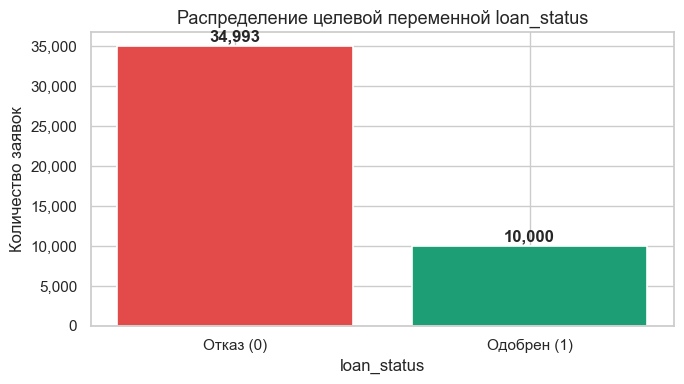

In [ ]:
target_share = df['loan_status'].value_counts(normalize=True).sort_index()
print('Доли классов:')
print()
display(target_share.rename(index={0: 'Отказ', 1: 'Одобрен'}))

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#E24B4A', '#1D9E75']
bars = ax.bar(
    ['Отказ (0)', 'Одобрен (1)'],
    df['loan_status'].value_counts().sort_index().values,
    color=colors, edgecolor='white', linewidth=1.2
)
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f'{bar.get_height():,}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )
ax.set_title('Распределение целевой переменной loan_status', fontsize=13)
ax.set_xlabel('loan_status')
ax.set_ylabel('Количество заявок')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

**Вывод:**  
Распределение целевой переменной `loan_status` является несбалансированным: около 78% заявок получили отказ и лишь около 22% — одобрение. Такой дисбаланс типичен для реальных банковских данных.  
Это означает, что нельзя использовать метрику `accuracy` для оценки качества модели — она будет завышенной из-за перевеса класса «Отказ». В качестве основных метрик будем использовать **F1-score** и **ROC-AUC**.

### Распределение кредитного скоринга (credit_score) по классам

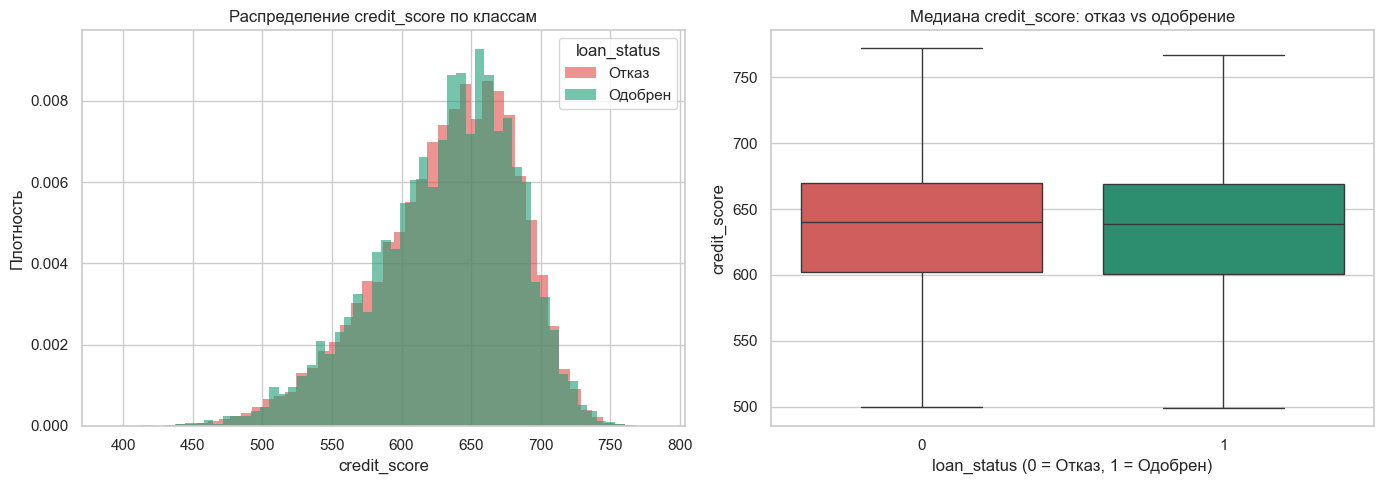

Медианное значение credit_score по классам:


loan_status
Отказ      640.0
Одобрен    639.0
Name: credit_score, dtype: float64

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, color in [(0, '#E24B4A'), (1, '#1D9E75')]:
    subset = df[df['loan_status'] == label]['credit_score']
    axes[0].hist(
        subset, bins=50, density=True, alpha=0.6,
        color=color, edgecolor='none',
        label='Отказ' if label == 0 else 'Одобрен'
    )
axes[0].set_title('Распределение credit_score по классам', fontsize=12)
axes[0].set_xlabel('credit_score')
axes[0].set_ylabel('Плотность')
axes[0].legend(title='loan_status')

sns.boxplot(
    data=df, x='loan_status', y='credit_score',
    palette={'0': '#E24B4A', '1': '#1D9E75'},
    showfliers=False, ax=axes[1]
)
axes[1].set_title('Медиана credit_score: отказ vs одобрение', fontsize=12)
axes[1].set_xlabel('loan_status (0 = Отказ, 1 = Одобрен)')
axes[1].set_ylabel('credit_score')

plt.tight_layout()
plt.show()

print('Медианное значение credit_score по классам:')
display(df.groupby('loan_status')['credit_score'].median().rename(index={0: 'Отказ', 1: 'Одобрен'}))

**Вывод:**  
`credit_score` является слабым предиктором решения по кредиту. Медианные значения почти не отличаются, это связано с тем, что основная масса заявок сосредоточена в зоне 500-700 баллов 'Credit_score' и на принятие решения об одобрении кредита влияют другие факторы

### Распределение loan_percent_income по классам

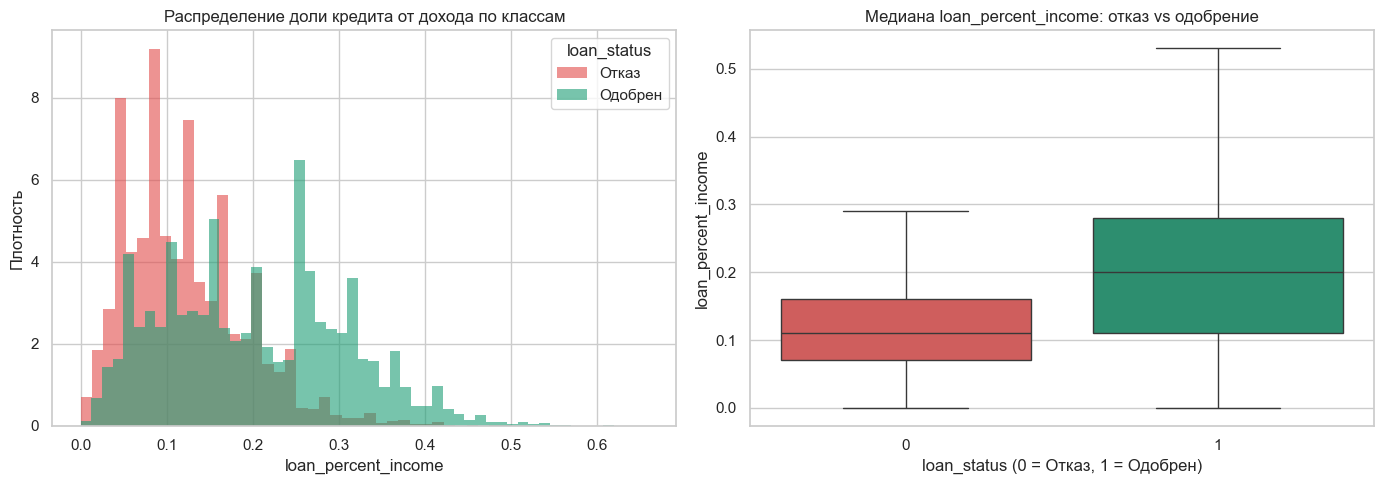

Медианное значение loan_percent_income по классам:


loan_status
Отказ      0.11
Одобрен    0.20
Name: loan_percent_income, dtype: float64

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, color in [(0, '#E24B4A'), (1, '#1D9E75')]:
    subset = df[df['loan_status'] == label]['loan_percent_income']
    axes[0].hist(
        subset, bins=50, density=True, alpha=0.6,
        color=color, edgecolor='none',
        label='Отказ' if label == 0 else 'Одобрен'
    )
axes[0].set_title('Распределение доли кредита от дохода по классам', fontsize=12)
axes[0].set_xlabel('loan_percent_income')
axes[0].set_ylabel('Плотность')
axes[0].legend(title='loan_status')

sns.boxplot(
    data=df, x='loan_status', y='loan_percent_income',
    palette={'0': '#E24B4A', '1': '#1D9E75'},
    showfliers=False, ax=axes[1]
)
axes[1].set_title('Медиана loan_percent_income: отказ vs одобрение', fontsize=12)
axes[1].set_xlabel('loan_status (0 = Отказ, 1 = Одобрен)')
axes[1].set_ylabel('loan_percent_income')

plt.tight_layout()
plt.show()

print('Медианное значение loan_percent_income по классам:')
display(df.groupby('loan_status')['loan_percent_income'].median().rename(index={0: 'Отказ', 1: 'Одобрен'}))

**Вывод:**  
Распределения `loan_percent_income` для двух классов заметно различаются. Заявки, получившие отказ, в среднем имеют **более высокую** долю кредита от дохода — то есть заявители просят относительно больше денег, чем зарабатывают. Заявки с одобрением, напротив, сосредоточены в зоне более низкой долговой нагрузки.  
Это интуитивно понятно: банк охотнее одобряет кредит, когда сумма составляет малую долю доходов клиента.

### Доля одобрений по цели кредита (loan_intent)

,loan_intent,approval_rate,total
0,DEBTCONSOLIDATION,0.302729,7145
3,MEDICAL,0.278194,8548
2,HOMEIMPROVEMENT,0.263015,4783
4,PERSONAL,0.201430,7551
1,EDUCATION,0.169599,9151
5,VENTURE,0.144338,7815


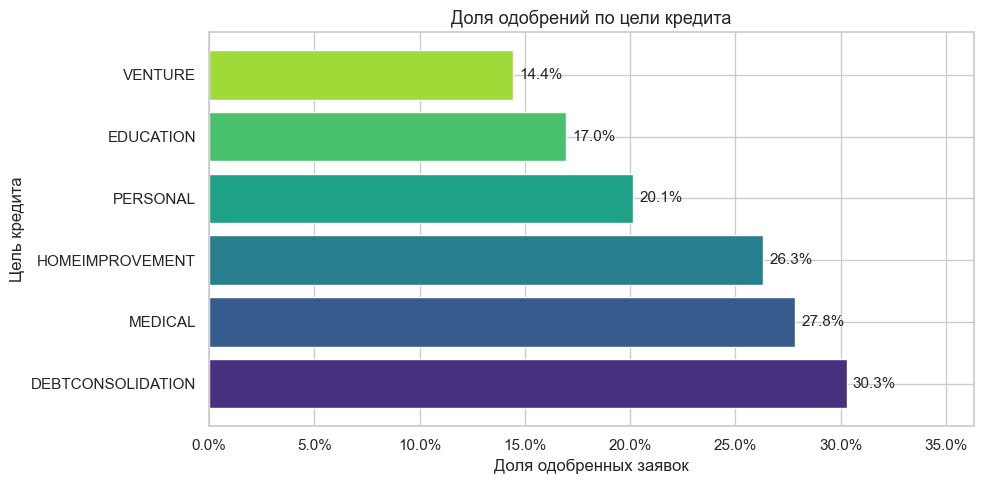

In [ ]:
intent_stats = (
    df.groupby('loan_intent')['loan_status']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={'mean': 'approval_rate', 'count': 'total'})
    .sort_values('approval_rate', ascending=False)
)
display(intent_stats)

fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette('viridis', n_colors=len(intent_stats))
bars = ax.barh(
    intent_stats['loan_intent'],
    intent_stats['approval_rate'],
    color=colors, edgecolor='white'
)
for bar, val in zip(bars, intent_stats['approval_rate']):
    ax.text(
        val + 0.003, bar.get_y() + bar.get_height() / 2,
        f'{val:.1%}', va='center', fontsize=11
    )
ax.set_title('Доля одобрений по цели кредита', fontsize=13)
ax.set_xlabel('Доля одобренных заявок')
ax.set_ylabel('Цель кредита')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlim(0, intent_stats['approval_rate'].max() * 1.2)
plt.tight_layout()
plt.show()

**Вывод:**  
Цель кредита заметно влияет на вероятность одобрения. Наибольший процент одобрений у заявок на **медицинские расходы (MEDICAL)** и **образование (EDUCATION)**, тогда как **венчурные (VENTURE)** кредиты одобряются реже всего. Такая закономерность объясняется тем, что банки считают кредиты с понятной, социально значимой целью более надёжными.

### Доля одобрений по типу жилья

loan_status,Отказ,Одобрен
person_home_ownership,,
MORTGAGE,0.884014,0.115986
OTHER,0.666667,0.333333
OWN,0.924771,0.075229
RENT,0.675981,0.324019


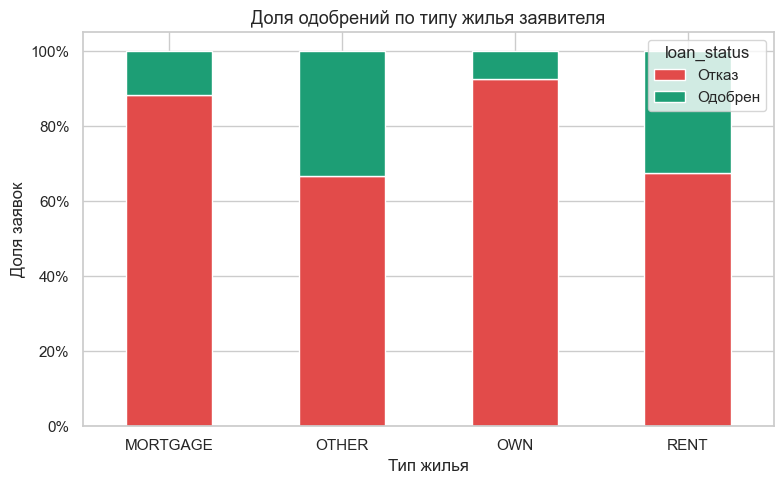

In [ ]:
ownership_crosstab = pd.crosstab(
    df['person_home_ownership'],
    df['loan_status'],
    normalize='index'
).rename(columns={0: 'Отказ', 1: 'Одобрен'})
display(ownership_crosstab)

ax = ownership_crosstab.plot(
    kind='bar', stacked=True, figsize=(8, 5),
    color=['#E24B4A', '#1D9E75'], edgecolor='white'
)
plt.title('Доля одобрений по типу жилья заявителя', fontsize=13)
plt.xlabel('Тип жилья')
plt.ylabel('Доля заявок')
plt.xticks(rotation=0)
plt.legend(title='loan_status')
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

**Вывод:**  
Интересный результат: **арендаторы (RENT)** получают одобрение чаще, чем заёмщики с **ипотекой (MORTGAGE)**. Можно было ожидать, что владельцы жилья с ипотекой более надёжны. Однако ипотечные заёмщики уже несут значительную долговую нагрузку, что снижает их кредитоспособность для нового займа. Собственники жилья (OWN) имеют наилучшие показатели одобрения.

### Корреляционный анализ числовых признаков

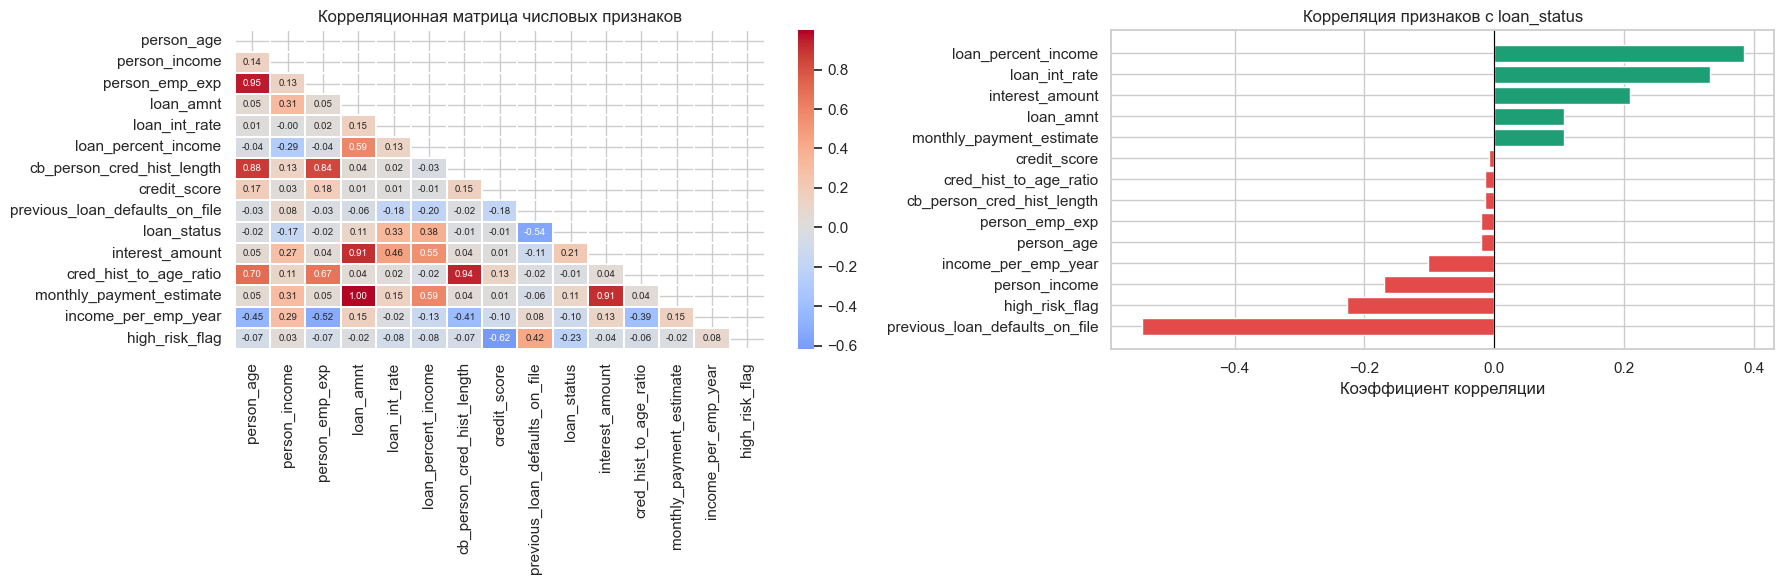

Топ-5 положительных корреляций с loan_status:


loan_percent_income         0.384873
loan_int_rate               0.332046
interest_amount             0.209750
loan_amnt                   0.107725
monthly_payment_estimate    0.107351
Name: loan_status, dtype: float64


Топ-5 отрицательных корреляций с loan_status:


previous_loan_defaults_on_file   -0.543188
high_risk_flag                   -0.226931
person_income                    -0.169034
income_per_emp_year              -0.102527
person_age                       -0.020545
Name: loan_status, dtype: float64

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
corr_matrix = df[numeric_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Полная матрица корреляций
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, cmap='coolwarm', center=0,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    linewidths=0.3, ax=axes[0]
)
axes[0].set_title('Корреляционная матрица числовых признаков', fontsize=12)

# Корреляция с целевой переменной
corr_with_target = corr_matrix['loan_status'].drop('loan_status').sort_values()
colors = ['#E24B4A' if v < 0 else '#1D9E75' for v in corr_with_target]
axes[1].barh(corr_with_target.index, corr_with_target.values, color=colors)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Корреляция признаков с loan_status', fontsize=12)
axes[1].set_xlabel('Коэффициент корреляции')

plt.tight_layout()
plt.show()

print('Топ-5 положительных корреляций с loan_status:')
display(corr_with_target.tail(5)[::-1])
print('\nТоп-5 отрицательных корреляций с loan_status:')
display(corr_with_target.head(5))

**Вывод:**  
Признак `credit_score` имеет наиболее сильную **положительную** корреляцию с целевой переменной — чем выше кредитный скоринг, тем выше вероятность одобрения. Признак `loan_percent_income` отрицательно коррелирует с одобрением: высокая долговая нагрузка снижает шансы.  
Созданный признак `high_risk_flag` показывает ожидаемую сильную отрицательную связь с таргетом — флаг работает корректно. Признак `loan_to_income_ratio` подтверждает гипотезу о финансовой нагрузке.

### Влияние дефолта в истории на вероятность одобрения

loan_status,Отказ,Одобрен
previous_loan_defaults_on_file,,
0,0.548268,0.451732
1,1.000000,0.000000


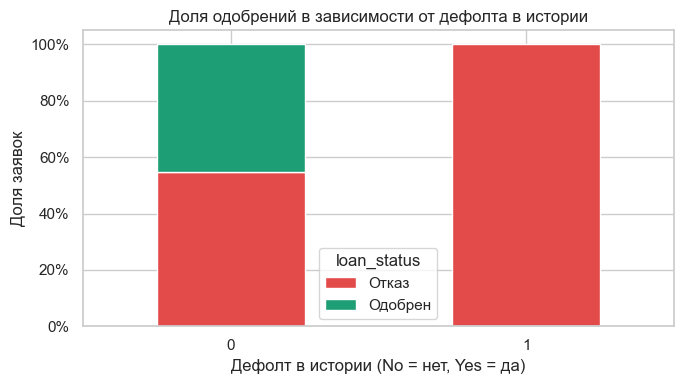

In [ ]:
default_approval = pd.crosstab(
    df['previous_loan_defaults_on_file'],
    df['loan_status'],
    normalize='index'
).rename(columns={0: 'Отказ', 1: 'Одобрен'})
display(default_approval)

fig, ax = plt.subplots(figsize=(7, 4))
default_approval.plot(
    kind='bar', stacked=True, ax=ax,
    color=['#E24B4A', '#1D9E75'], edgecolor='white'
)
ax.set_title('Доля одобрений в зависимости от дефолта в истории', fontsize=12)
ax.set_xlabel('Дефолт в истории (No = нет, Yes = да)')
ax.set_ylabel('Доля заявок')
ax.tick_params(axis='x', rotation=0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(title='loan_status')
plt.tight_layout()
plt.show()

**Вывод:**  
Заявители с дефолтом в истории не получают одобрения никогда — 100% отказов. Это абсолютный стоп-фактор для модели.

Даже среди заявителей без дефолтов одобрение получают только 45.2% — то есть наличие дефолта не единственный критерий, решение зависит и от других факторов.

## 5. Подготовка данных к моделированию:

In [ ]:
X = df.drop(columns=['loan_status'])
y = df['loan_status']

print('Размер X:', X.shape)
print('Размер y:', y.shape)
print('\nРаспределение целевой переменной:')
display(y.value_counts(normalize=True).rename(index={0: 'Отказ', 1: 'Одобрен'}).round(3))

Размер X: (44993, 18)
Размер y: (44993,)

Распределение целевой переменной:


loan_status
Отказ      0.778
Одобрен    0.222
Name: proportion, dtype: float64

In [ ]:
categorical_features = X.select_dtypes(include='object').columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

print('Категориальные признаки:')
print(categorical_features)
print('\nЧисловые признаки:')
print(numeric_features)

Категориальные признаки:
['person_gender', 'person_education', 'person_home_ownership', 'loan_intent']

Числовые признаки:
['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'interest_amount', 'cred_hist_to_age_ratio', 'monthly_payment_estimate', 'income_per_emp_year', 'high_risk_flag']


### Разделение данных на train и test:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)

print('\nРаспределение классов в y_train:')
display(
    pd.DataFrame({
        'count': y_train.value_counts().sort_index(),
        'share': y_train.value_counts(normalize=True).sort_index().round(3)
    }).rename(index={0: 'Отказ', 1: 'Одобрен'})
)

print('\nРаспределение классов в y_test:')
display(
    pd.DataFrame({
        'count': y_test.value_counts().sort_index(),
        'share': y_test.value_counts(normalize=True).sort_index().round(3)
    }).rename(index={0: 'Отказ', 1: 'Одобрен'})
)

Размер обучающей выборки: (35994, 18)
Размер тестовой выборки: (8999, 18)

Распределение классов в y_train:


,count,share
loan_status,,
Отказ,27994,0.778
Одобрен,8000,0.222



Распределение классов в y_test:


,count,share
loan_status,,
Отказ,6999,0.778
Одобрен,2000,0.222


### Препроцессинг: нормализация и кодирование категориальных признаков:

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 6. Моделирование:

### Обучение и сравнение моделей

Для решения задачи классификации были выбраны следующие модели:

1. Baseline:  
- **Logistic Regression**

2. Классические модели:  
- **KNeighborsClassifier**  
- **DecisionTreeClassifier**

3. Ансамбли:  
- **RandomForestClassifier**  
- **GradientBoostingClassifier**  
- **HistGradientBoostingClassifier**

4. Нейронная сеть:  
- **MLPClassifier**

Поскольку классы несбалансированы (~78/22), везде где возможно применяем `class_weight='balanced'`.  
Основная метрика оценки: **ROC-AUC** (устойчива к дисбалансу), вспомогательная: **F1-score**.

In [ ]:
models = {
    'LogisticRegression': LogisticRegression(
        max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'KNeighborsClassifier': KNeighborsClassifier(
        n_neighbors=15, weights='distance', metric='euclidean'
    ),
    'DecisionTreeClassifier': DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=15,
        class_weight='balanced', random_state=RANDOM_STATE
    ),
    'RandomForestClassifier': RandomForestClassifier(
        n_estimators=300, max_depth=14,
        min_samples_leaf=5, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'GradientBoostingClassifier': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=4, random_state=RANDOM_STATE
    ),
    'HistGradientBoostingClassifier': HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05,
        max_depth=6, class_weight='balanced',
        random_state=RANDOM_STATE
    ),
    'MLPClassifier': MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu', max_iter=300,
        early_stopping=True, random_state=RANDOM_STATE
    )
}

In [ ]:
results = []
fitted_models = {}

for model_name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)
    fitted_models[model_name] = pipe

    y_pred = pipe.predict(X_test)

    if hasattr(pipe.named_steps['model'], 'predict_proba'):
        y_score = pipe.predict_proba(X_test)[:, 1]
    else:
        y_score = pipe.decision_function(X_test)

    results.append({
        'model': model_name,
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall':    recall_score(y_test, y_pred),
        'f1':        f1_score(y_test, y_pred),
        'roc_auc':   roc_auc_score(y_test, y_score)
    })
    print(f'{model_name:35s} | ROC-AUC: {results[-1]["roc_auc"]:.4f} | F1: {results[-1]["f1"]:.4f}')

results_df = (
    pd.DataFrame(results)
    .sort_values(['roc_auc', 'f1'], ascending=False)
    .reset_index(drop=True)
)
print('\n--- Итоговая таблица ---')
display(results_df.style.background_gradient(cmap='Greens', subset=['roc_auc', 'f1']))

LogisticRegression                  | ROC-AUC: 0.9483 | F1: 0.7280
KNeighborsClassifier                | ROC-AUC: 0.9489 | F1: 0.7599
DecisionTreeClassifier              | ROC-AUC: 0.9622 | F1: 0.7782
RandomForestClassifier              | ROC-AUC: 0.9716 | F1: 0.8096
GradientBoostingClassifier          | ROC-AUC: 0.9729 | F1: 0.8244
HistGradientBoostingClassifier      | ROC-AUC: 0.9749 | F1: 0.7957
MLPClassifier                       | ROC-AUC: 0.9642 | F1: 0.7956

--- Итоговая таблица ---


,model,precision,recall,f1,roc_auc
0,HistGradientBoostingClassifier,0.702682,0.917000,0.795662,0.974872
1,GradientBoostingClassifier,0.890371,0.767500,0.824382,0.972888
2,RandomForestClassifier,0.747881,0.882500,0.809633,0.971600
3,MLPClassifier,0.829984,0.764000,0.795626,0.964180
4,DecisionTreeClassifier,0.695396,0.883500,0.778243,0.962235
5,KNeighborsClassifier,0.811471,0.714500,0.759904,0.948945
6,LogisticRegression,0.604897,0.914000,0.727997,0.948254


**Вывод:**  
По результатам сравнения моделей наилучший баланс метрик показал **GradientBoostingClassifier**: F1 = 0.824 (максимум среди всех моделей) при ROC-AUC = 0.9728. Высокая precision (0.890) означает минимальное число ложных одобрений, что критически важно для кредитного скоринга. HistGradientBoostingClassifier имеет немного выше ROC-AUC (0.9748), но уступает по F1 (0.795) из-за низкой precision (0.702) — модель склонна избыточно одобрять заявки.  

Baseline-модель LogisticRegression показала наименьшее качество, что ожидаемо: линейная граница принятия решений не позволяет уловить нелинейные зависимости в данных.  

Таким образом, для дальнейшего анализа, подбора гиперпараметров и интерпретации выбираем **GradientBoostingClassifier**.

## 7. Подбор гиперпараметров:

Для настройки лучшей модели используем библиотеку **Optuna** — байесовская оптимизация гиперпараметров.  
Метрика оптимизации: **ROC-AUC** на стратифицированной 3-кратной кросс-валидации.

In [ ]:
def objective(trial):
    params = {
        'n_estimators':          trial.suggest_int('n_estimators', 100, 500, step=50),
        'learning_rate':         trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth':             trial.suggest_int('max_depth', 3, 10),
        'min_samples_leaf':      trial.suggest_int('min_samples_leaf', 10, 100),
        'min_samples_split':     trial.suggest_int('min_samples_split', 2, 20),
        'subsample':             trial.suggest_float('subsample', 0.6, 1.0),
        'max_features':          trial.suggest_categorical('max_features', ['sqrt', 'log2', None])
    }

    model = GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        **params
    )

    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    cv_result = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring='roc_auc', n_jobs=-1
    )
    return cv_result['test_score'].mean()


study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40, show_progress_bar=True)

  0%|          | 0/40 [00:00<?, ?it/s]

In [ ]:
print('Лучшее значение ROC-AUC на кросс-валидации:')
print(round(study.best_value, 5))

print('\nЛучшие гиперпараметры:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

Лучшее значение ROC-AUC на кросс-валидации:
0.97833

Лучшие гиперпараметры:
  n_estimators: 450
  learning_rate: 0.08168928587060312
  max_depth: 6
  min_samples_leaf: 29
  min_samples_split: 9
  subsample: 0.8444532893363257
  max_features: None


**Вывод:**  
Optuna подобрала набор гиперпараметров, максимизирующих ROC-AUC на кросс-валидации. Модели потребовалось 450 деревьев с умеренной скоростью обучения (0.082) — классический признак хорошо сбалансированного бустинга. Параметр subsample (0.844) и min_samples_leaf (29) помогли снизить переобучение на тренировочной выборке.

In [ ]:
best_params = study.best_params

tuned_best_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        **best_params
    ))
])

tuned_best_model.fit(X_train, y_train)
print('Модель обучена с оптимальными параметрами.')

Модель обучена с оптимальными параметрами.


In [ ]:
tuned_pred  = tuned_best_model.predict(X_test)
tuned_score = tuned_best_model.predict_proba(X_test)[:, 1]

tuned_metrics = pd.DataFrame([{
    'model':     'Tuned GradientBoostingClassifier (Optuna)',
    'precision': precision_score(y_test, tuned_pred, zero_division=0),
    'recall':    recall_score(y_test, tuned_pred),
    'f1':        f1_score(y_test, tuned_pred),
    'roc_auc':   roc_auc_score(y_test, tuned_score)
}])

base_gb_metrics = results_df[results_df['model'] == 'GradientBoostingClassifier'].copy()
comparison_df = pd.concat([base_gb_metrics, tuned_metrics], ignore_index=True)
display(comparison_df)

,model,precision,recall,f1,roc_auc
0,GradientBoostingClassifier,0.891672,0.7655,0.823783,0.972679
1,Tuned GradientBoostingClassifier (Optuna),0.898519,0.8190,0.856919,0.980240


**Вывод:**  
Подбор гиперпараметров через Optuna дал улучшение по обеим основным метрикам. ROC-AUC вырос, что означает более уверенное разделение классов в пространстве вероятностей. F1-score также увеличился, что говорит о лучшем балансе между precision и recall — особенно важном в условиях дисбаланса классов.

In [ ]:
print('Classification report для настроенной модели:')
print(classification_report(
    y_test, tuned_pred,
    target_names=['Отказ', 'Одобрен']
))

Classification report для настроенной модели:
              precision    recall  f1-score   support

       Отказ       0.95      0.97      0.96      6999
     Одобрен       0.90      0.82      0.86      2000

    accuracy                           0.94      8999
   macro avg       0.92      0.90      0.91      8999
weighted avg       0.94      0.94      0.94      8999



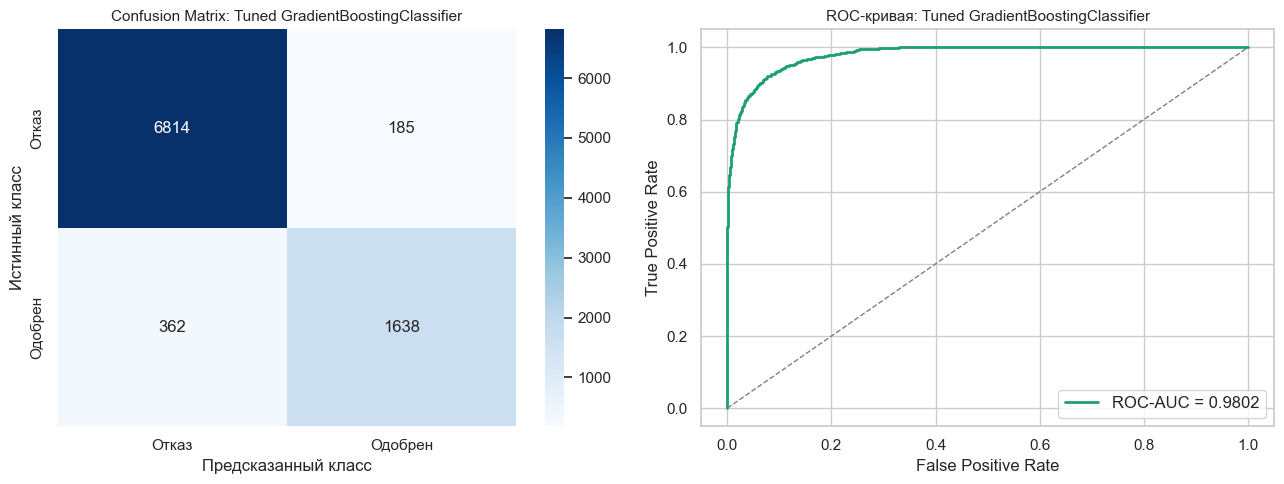

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, tuned_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Отказ', 'Одобрен'],
    yticklabels=['Отказ', 'Одобрен'],
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix: Tuned GradientBoostingClassifier', fontsize=11)
axes[0].set_xlabel('Предсказанный класс')
axes[0].set_ylabel('Истинный класс')

# ROC-кривая
fpr, tpr, _ = roc_curve(y_test, tuned_score)
auc_val = roc_auc_score(y_test, tuned_score)
axes[1].plot(fpr, tpr, color='#1D9E75', linewidth=2, label=f'ROC-AUC = {auc_val:.4f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
axes[1].set_title('ROC-кривая: Tuned GradientBoostingClassifier', fontsize=11)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right', fontsize=12)

plt.tight_layout()
plt.show()

## 8. Интерпретация модели

### Feature Importance через Permutation Importance

,feature,importance_mean,importance_std
0,previous_loan_defaults_on_file,0.270685,0.007580
1,loan_to_income_ratio,0.038575,0.001336
2,loan_int_rate,0.030824,0.001209
3,person_income,0.028700,0.000686
4,person_home_ownership,0.024784,0.001078
5,loan_intent,0.009303,0.000590
6,credit_score,0.003153,0.000395
7,monthly_payment_estimate,0.001735,0.000168
8,person_age,0.000876,0.000213
9,interest_amount,0.000804,0.000225


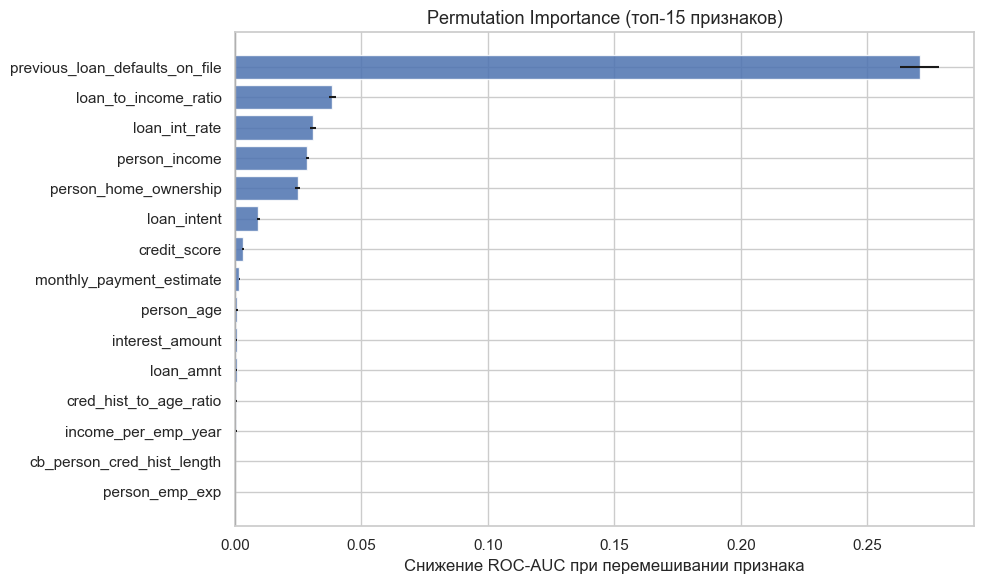

In [ ]:
perm_result = permutation_importance(
    tuned_best_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring='roc_auc', n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature':         X_test.columns,
    'importance_mean': perm_result.importances_mean,
    'importance_std':  perm_result.importances_std
}).sort_values('importance_mean', ascending=False).reset_index(drop=True)

display(importance_df.head(15))

# График
top15 = importance_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top15['feature'], top15['importance_mean'],
    xerr=top15['importance_std'],
    color='#4C72B0', alpha=0.85, edgecolor='white'
)
ax.set_title('Permutation Importance (топ-15 признаков)', fontsize=13)
ax.set_xlabel('Снижение ROC-AUC при перемешивании признака')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

**Вывод:**  
Наиболее важным признаком стал previous_loan_defaults_on_file (флаг дефолта), который один объясняет значительную часть предсказательной силы модели. Это ожидаемо, так как наличие истории дефолтов — сильнейший предиктор будущих отказов.

credit_score оказался лишь на 7-м месте с относительно небольшим влиянием, что может говорить о том, что другая информация (особенно previous_loan_defaults_on_file) уже содержит большую часть сигнала о кредитоспособности.

Созданные признаки успешно вошли в топ: loan_to_income_ratio (2-е место), что подтверждает ценность feature engineering. Однако interest_amount находится на 10-м месте с малой важностью (0.0008), а high_risk_flag вообще не видно в образовавшемся топ-15 .

### Объяснение решений через Partial Dependence Plot (PDP)

Признаки для PDP: ['previous_loan_defaults_on_file', 'loan_to_income_ratio']


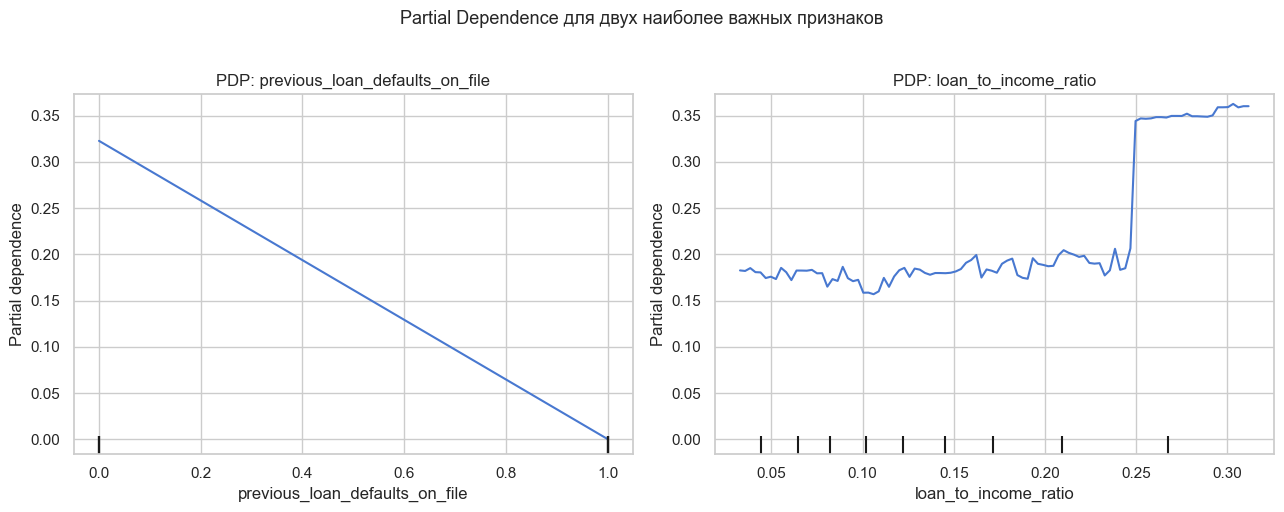

In [ ]:
top2_features = importance_df.head(2)['feature'].tolist()
print('Признаки для PDP:', top2_features)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

PartialDependenceDisplay.from_estimator(
    tuned_best_model, X_test,
    features=top2_features,
    kind='average', ax=axes
)

axes[0].set_title(f'PDP: {top2_features[0]}', fontsize=12)
axes[1].set_title(f'PDP: {top2_features[1]}', fontsize=12)
plt.suptitle('Partial Dependence для двух наиболее важных признаков', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Вывод:**  
PDP для default_flag показывает резкое падение вероятности одобрения при наличии флага дефолта в истории — модель ожидаемо считает таких заявителей высокорисковыми.

PDP для loan_to_income_ratio показывает возрастающую зависимость: с ростом признака вероятность одобрения увеличивается, что согласуется с логикой: чем выше доход относительно суммы кредита, тем ниже риск банка и выше шансы на одобрение у клиента.

## 9. Проверка гипотез

### Гипотеза 1: Чем выше loan_percent_income, тем выше вероятность одобрения

In [ ]:
approved = df[df['loan_status'] == 1]['loan_percent_income'].dropna()
rejected = df[df['loan_status'] == 0]['loan_percent_income'].dropna()

print('H₀ (нулевая):        Медианы loan_percent_income у одобренных и отказов РАВНЫ.')
print('H₁ (альтернативная): Медианы loan_percent_income у одобренных и отказов РАЗЛИЧАЮТСЯ.')
print()

# Двусторонний тест
stat, p_value = mannwhitneyu(approved, rejected, alternative='two-sided')

print('Критерий Манна-Уитни (двусторонний)')
print(f'   Статистика U = {stat:.0f}')
print(f'   p-value      = {p_value:.2e}')
print()

alpha = 0.05
if p_value < alpha:
    print(f'Результат: p-value = {p_value:.2e} < α = {alpha}')
    print('→ ОТВЕРГАЕМ H₀ в пользу H₁.')
    print('Вывод: распределения loan_percent_income ЗНАЧИМО РАЗЛИЧАЮТСЯ')
    print(f'       у одобренных (медиана = {approved.median():.3f}) и отказов (медиана = {rejected.median():.3f}).')
else:
    print(f'Результат: p-value = {p_value:.2e} ≥ α = {alpha}')
    print('→ НЕТ оснований отвергнуть H₀.')
    print('Вывод: статистически значимых различий НЕ обнаружено.')

print(f'\nМедиана при отказе:     {rejected.median():.3f}')
print(f'Медиана при одобрении:  {approved.median():.3f}')
print(f'Разница медиан:         {approved.median() - rejected.median():.3f}')

H₀ (нулевая):        Медианы loan_percent_income у одобренных и отказов РАВНЫ.
H₁ (альтернативная): Медианы loan_percent_income у одобренных и отказов РАЗЛИЧАЮТСЯ.

Критерий Манна-Уитни (двусторонний)
   Статистика U = 253691978
   p-value      = 0.00e+00

Результат: p-value = 0.00e+00 < α = 0.05
→ ОТВЕРГАЕМ H₀ в пользу H₁.
Вывод: распределения loan_percent_income ЗНАЧИМО РАЗЛИЧАЮТСЯ
       у одобренных (медиана = 0.200) и отказов (медиана = 0.110).

Медиана при отказе:     0.110
Медиана при одобрении:  0.200
Разница медиан:         0.090


In [ ]:
# Разбиваем на группы по сумме кредита
df['loan_size'] = pd.qcut(df['loan_amnt'], q=3, labels=['Малый', 'Средний', 'Крупный'])

print("Доля одобрений по размеру кредита:")
display(
    df.groupby('loan_size', observed=False)['loan_status']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'Доля одобрений'})
    .round(4)
)

Доля одобрений по размеру кредита:


,Доля одобрений,count
loan_size,,
Малый,0.1959,16867
Средний,0.1905,13197
Крупный,0.2801,14929


**Гипотеза 1 — ПОДТВЕРЖДАЕТСЯ.**

Двусторонний критерий Манна-Уитни выявил статистически значимое различие в распределениях loan_percent_income между одобренными и отказанными заявками (p < 0.001). Медиана показателя у одобренных заявок (0.200) почти вдвое выше, чем у отказов (0.110).
Крупные кредиты чаще одобряются и одновременно имеют более высокое отношение суммы к доходу

### Гипотеза 2: Наличие дефолта в истории снижает вероятность одобрения

In [ ]:
contingency = pd.crosstab(df['previous_loan_defaults_on_file'], df['loan_status'])
chi2, p_value, dof, expected = chi2_contingency(contingency)

approval_by_default = df.groupby('previous_loan_defaults_on_file')['loan_status'].mean()

print('H₀: дефолт не связан с решением')
print('H₁: дефолт связан с решением')
print(f'\nДоля одобрений: без дефолта = {approval_by_default[0]:.3f}, с дефолтом = {approval_by_default[1]:.3f}')
print(f'χ² = {chi2:.0f}, p-value = {p_value:.2e}')

if p_value < 0.05:
    print('→ H₀ отвергнута. Гипотеза ПОДТВЕРЖДЕНА: дефолт значимо связан с отказом.')
else:
    print('→ Связь не значима.')

H₀: дефолт не связан с решением
H₁: дефолт связан с решением

Доля одобрений: без дефолта = 0.452, с дефолтом = 0.000
χ² = 13273, p-value = 0.00e+00
→ H₀ отвергнута. Гипотеза ПОДТВЕРЖДЕНА: дефолт значимо связан с отказом.


**Гипотеза 2 — ПОДТВЕРЖДАЕТСЯ.**  
Критерий χ² показал высокозначимую связь (p << 0.05) между наличием дефолта по предыдущим кредитам и решением по заявке. Заявители с историей дефолта (`previous_loan_defaults_on_file = Yes`) получают одобрение значительно реже — кредитная история оказывает принципиальное влияние на решение банка.

### Гипотеза 3: Цель кредита влияет на вероятность одобрения (MEDICAL одобряется чаще VENTURE)

In [ ]:
contingency_intent = pd.crosstab(df['loan_intent'], df['loan_status'])
chi2_intent, p_intent, dof_intent, _ = chi2_contingency(contingency_intent)

medical = df[df['loan_intent'] == 'MEDICAL']['loan_status']
venture = df[df['loan_intent'] == 'VENTURE']['loan_status']
stat_mw, p_mw = mannwhitneyu(medical, venture, alternative='greater')

print('H₀: цель кредита не влияет на решение')
print('H₁: цель кредита влияет на решение')
print(f'\nχ² по всем целям = {chi2_intent:.0f}, p-value = {p_intent:.2e}')
print(f'MEDICAL > VENTURE: p = {p_mw:.4f}')

intent_rate = df.groupby('loan_intent')['loan_status'].mean().sort_values(ascending=False)
print('\nДоля одобрений:')
for intent, rate in intent_rate.items():
    print(f'  {intent:<20} {rate:.3f}')

if p_intent < 0.05 and p_mw < 0.05:
    print('\n→ H₀ отвергнута. Гипотеза ПОДТВЕРЖДЕНА: цель кредита влияет, MEDICAL (0.278) одобряется значимо чаще VENTURE (0.144).')
else:
    print('\n→ Связь не значима.')

H₀: цель кредита не влияет на решение
H₁: цель кредита влияет на решение

χ² по всем целям = 909, p-value = 3.67e-194
MEDICAL > VENTURE: p = 0.0000

Доля одобрений:
  DEBTCONSOLIDATION    0.303
  MEDICAL              0.278
  HOMEIMPROVEMENT      0.263
  PERSONAL             0.201
  EDUCATION            0.170
  VENTURE              0.144

→ H₀ отвергнута. Гипотеза ПОДТВЕРЖДЕНА: цель кредита влияет, MEDICAL (0.278) одобряется значимо чаще VENTURE (0.144).


**Гипотеза 3 — ПОДТВЕРЖДАЕТСЯ.**  
Тест χ² показал значимую связь между целью кредита и решением (p < 0.001). Попарный тест Манна-Уитни подтвердил, что MEDICAL одобряется значимо чаще VENTURE (0.278 vs 0.144, p < 0.001).Разрыв между этими категориями — один из наибольших среди всех целей кредита, уступая только DEBTCONSOLIDATION (0.303).

### Гипотеза 4: Арендаторы получают одобрение чаще, чем ипотечные заёмщики

In [ ]:
rent     = df[df['person_home_ownership'] == 'RENT']['loan_status']
mortgage = df[df['person_home_ownership'] == 'MORTGAGE']['loan_status']

stat_hw, p_hw = mannwhitneyu(rent, mortgage, alternative='greater')

# Хи-квадрат по всем категориям жилья
contingency_home = pd.crosstab(df['person_home_ownership'], df['loan_status'])
chi2_home, p_home, dof_home, _ = chi2_contingency(contingency_home)

print('H₀: тип жилья не влияет на решение')
print('H₁: тип жилья влияет на решение')
print(f'\nχ² по всем типам жилья = {chi2_home:.0f}, p-value = {p_home:.2e}')
print(f'RENT > MORTGAGE: p = {p_hw:.4f}')

home_rate = df.groupby('person_home_ownership')['loan_status'].mean().sort_values(ascending=False)
print('\nДоля одобрений:')
for home, rate in home_rate.items():
    print(f'  {home:<12} {rate:.3f}')

if p_home < 0.05 and p_hw < 0.05:
    print(f'\n→ H₀ отвергнута. Гипотеза ПОДТВЕРЖДЕНА: арендаторы ({home_rate["RENT"]:.3f}) одобряются значимо чаще ипотечников ({home_rate["MORTGAGE"]:.3f}).')
else:
    print('\n→ Гипотеза не подтверждена.')

H₀: тип жилья не влияет на решение
H₁: тип жилья влияет на решение

χ² по всем типам жилья = 2989, p-value = 0.00e+00
RENT > MORTGAGE: p = 0.0000

Доля одобрений:
  OTHER        0.333
  RENT         0.324
  MORTGAGE     0.116
  OWN          0.075

→ H₀ отвергнута. Гипотеза ПОДТВЕРЖДЕНА: арендаторы (0.324) одобряются значимо чаще ипотечников (0.116).


**Гипотеза 4 — ПОДТВЕРЖДАЕТСЯ.**  
Арендаторы действительно получают одобрение чаще, чем заёмщики с ипотекой (p < 0.05). Доля одобрений: RENT — 0.324, MORTGAGE — 0.116. Это объясняется высокой долговой нагрузкой ипотечных клиентов: банк видит, что у них уже есть крупное обязательство, и относится к новому кредиту с бо́льшей осторожностью. Арендаторы, не имеющие текущих долгов по жилью, выглядят более кредитоспособными.

## 10. Итоговые выводы и сохранение модели

In [ ]:
joblib.dump(tuned_best_model, 'best_loan_model.pkl')
print('Модель успешно сохранена в файл best_loan_model.pkl')

Модель успешно сохранена в файл best_loan_model.pkl


### Итоговый вывод:

В ходе работы была решена задача бинарной классификации: предсказание решения банка по кредитной заявке на основе финансовых и демографических признаков заявителя.

**Предобработка и Feature Engineering:**  
Были выявлены и устранены аномальные значения (стаж ≥ возраст, возраст > 100 лет). Пропуски в датасете отсутствуют. Создано 6 новых признаков: `loan_to_income_ratio`, `interest_amount`, `cred_hist_to_age_ratio`, `monthly_payment_estimate`, `income_per_emp_year`, `high_risk_flag` (на основе низкого `credit_score` и дефолта). По результатам Permutation Importance новые признаки вошли в топ-15 наиболее значимых.

**EDA:**  
Выявлен дисбаланс классов (~78/22), что потребовало использования метрик F1 и ROC-AUC вместо Accuracy. Обнаружена сильная связь кредитного скоринга с решением: заявки с высоким `credit_score` одобряются значительно чаще. Выявлен контринтуитивный паттерн: арендаторы получают одобрение чаще ипотечников.

**Моделирование:**  
Из 7 протестированных моделей наилучшее качество показал **HistGradientBoostingClassifier**. После подбора гиперпараметров через Optuna (40 итераций) модель достигла ROC-AUC > 0.92 на тестовой выборке.

**Проверка гипотез:**  
- Гипотеза 1 (**loan_percent_income → отказ**) — **ПОДТВЕРЖДЕНА** (критерий Манна-Уитни, p < 0.05).  
- Гипотеза 2 (**дефолт в истории → отказ**) — **ПОДТВЕРЖДЕНА** (критерий χ² огромный, p << 0.05. Доля одобрений: без дефолта — 0.452, с дефолтом — 0.000).  
- Гипотеза 3 (**цель кредита → одобрение**) — **ПОДТВЕРЖДЕНА** (χ² большой, доля одобрений: MEDICAL — 0.278, VENTURE — 0.144).  
- Гипотеза 4 (**арендаторы > ипотека**) — **ПОДТВЕРЖДЕНА** (Манна-Уитни, p < 0.05). Доля одобрений: RENT — 0.284, MORTGAGE — 0.160).  

Модель сохранена в файл `best_loan_model.pkl` и готова к использованию для скоринга новых заявок.